# Bab 12 – Cross-Validation and Model Evaluation Techniques

## Ringkasan Bab
Satu pembagian latih-uji bisa menyesatkan karena hasilnya bergantung pada pembagian acak itu. **Cross-validation (CV)** memberi estimasi
performa yang lebih stabil. Bab ini membahas berbagai skema CV (K-Fold, Stratified, Group, Time Series, Repeated, Leave-One-Out),
penerapannya di scikit-learn, seleksi model (termasuk **nested CV**), serta evaluasi kemampuan generalisasi lewat kurva validasi dan kurva belajar.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer, make_classification
from sklearn.model_selection import (KFold, StratifiedKFold, RepeatedStratifiedKFold, GroupKFold, TimeSeriesSplit, LeaveOneOut,
    ShuffleSplit, cross_val_score, cross_validate, cross_val_predict, GridSearchCV, learning_curve, validation_curve, permutation_test_score)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report
import warnings; warnings.filterwarnings("ignore")
X, y = load_breast_cancer(return_X_y=True)
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))

## 1. Pengantar Cross-Validation
Masalah *hold-out* tunggal: hasil bergantung pada satu pembagian acak, dan sebagian data tidak dipakai untuk melatih.
Pada **K-Fold CV**, data dibagi menjadi K lipatan; model dilatih K kali, tiap kali satu lipatan berbeda menjadi data uji.
Skor akhirnya adalah rata-rata K hasil (beserta simpangan bakunya). Pilihan umum K = 5 atau 10.

In [2]:
rng = np.random.RandomState(0)
for seed in range(5):
    from sklearn.model_selection import train_test_split
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.25, random_state=seed)
    print(f"hold-out seed {seed}: akurasi = {model.fit(Xtr, ytr).score(Xte, yte):.3f}")
s = cross_val_score(model, X, y, cv=KFold(5, shuffle=True, random_state=0))
print("5-fold CV:", s.round(3), "| rata-rata %.3f ± %.3f" % (s.mean(), s.std()))

hold-out seed 0: akurasi = 0.958
hold-out seed 1: akurasi = 0.979
hold-out seed 2: akurasi = 0.972
hold-out seed 3: akurasi = 0.972
hold-out seed 4: akurasi = 0.958
5-fold CV: [0.965 0.982 0.956 0.956 1.   ] | rata-rata 0.972 ± 0.017


## 2. Teknik Cross-Validation Lanjutan
| Skema | Kapan dipakai |
|---|---|
| `KFold` | data seimbang dan i.i.d. |
| `StratifiedKFold` | klasifikasi, proporsi kelas dijaga di tiap lipatan (default untuk classifier) |
| `RepeatedStratifiedKFold` | estimasi lebih stabil, data sedikit |
| `GroupKFold` | satu entitas (pasien, pengguna) punya banyak baris; entitas yang sama tidak boleh muncul di latih dan uji sekaligus |
| `TimeSeriesSplit` | data berurutan waktu; latih selalu mendahului uji |
| `LeaveOneOut` | data sangat kecil (mahal secara komputasi) |

In [3]:
Xi = np.arange(20).reshape(-1, 1); yi = np.r_[np.zeros(15), np.ones(5)]
print("StratifiedKFold: proporsi kelas 1 tiap lipatan uji:", [round(float(yi[t].mean()), 2) for _, t in StratifiedKFold(5).split(Xi, yi)])
print("TimeSeriesSplit (latih -> uji):")
for tr, te in TimeSeriesSplit(4).split(Xi): print("  latih", tr.min(), "-", tr.max(), "| uji", te.min(), "-", te.max())
groups = np.repeat(np.arange(5), 4)
for tr, te in GroupKFold(5).split(Xi, yi, groups): print("GroupKFold grup uji:", set(map(int, groups[te])), "| tidak ada di latih:", set(groups[te]).isdisjoint(groups[tr]))

StratifiedKFold: proporsi kelas 1 tiap lipatan uji: [0.25, 0.25, 0.25, 0.25, 0.25]
TimeSeriesSplit (latih -> uji):
  latih 0 - 3 | uji 4 - 7
  latih 0 - 7 | uji 8 - 11
  latih 0 - 11 | uji 12 - 15
  latih 0 - 15 | uji 16 - 19
GroupKFold grup uji: {4} | tidak ada di latih: True
GroupKFold grup uji: {3} | tidak ada di latih: True
GroupKFold grup uji: {2} | tidak ada di latih: True
GroupKFold grup uji: {1} | tidak ada di latih: True
GroupKFold grup uji: {0} | tidak ada di latih: True


## 3. Menerapkan Cross-Validation di scikit-learn
* `cross_val_score`: satu metrik.
* `cross_validate`: banyak metrik sekaligus + waktu latih/prediksi, bisa mengembalikan skor latih.
* `cross_val_predict`: prediksi *out-of-fold* untuk setiap data (berguna untuk confusion matrix).

Selalu masukkan preprocessing ke dalam `Pipeline` agar tidak ada kebocoran data antar lipatan.

In [4]:
res = cross_validate(model, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=0),
                     scoring=["accuracy", "precision", "recall", "f1", "roc_auc"], return_train_score=True)
pd.DataFrame(res).mean().round(3)

fit_time           0.005
score_time         0.008
test_accuracy      0.979
train_accuracy     0.988
test_precision     0.975
train_precision    0.986
test_recall        0.992
train_recall       0.995
test_f1            0.983
train_f1           0.991
test_roc_auc       0.995
train_roc_auc      0.998
dtype: float64

In [5]:
oof = cross_val_predict(model, X, y, cv=5)
print(classification_report(y, oof))
rep = cross_val_score(model, X, y, cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=0))
print("Repeated 5x5: %.3f ± %.3f (dari %d skor)" % (rep.mean(), rep.std(), len(rep)))

              precision    recall  f1-score   support

           0       0.99      0.96      0.97       212
           1       0.98      0.99      0.98       357

    accuracy                           0.98       569
   macro avg       0.98      0.98      0.98       569
weighted avg       0.98      0.98      0.98       569



Repeated 5x5: 0.977 ± 0.015 (dari 25 skor)


## 4. Teknik Seleksi Model
Membandingkan beberapa model dengan CV yang **sama** (fold yang sama) agar adil. Namun, bila CV yang sama dipakai untuk menyetel
hyperparameter *dan* melaporkan performa, hasilnya terlalu optimis. Solusinya **nested cross-validation**:
loop dalam untuk menyetel, loop luar untuk menilai.

In [6]:
cv = StratifiedKFold(5, shuffle=True, random_state=1)
cands = {"LogReg": model, "SVC": make_pipeline(StandardScaler(), SVC()), "RandomForest": RandomForestClassifier(200, random_state=0, n_jobs=-1)}
for n, m in cands.items():
    s = cross_val_score(m, X, y, cv=cv); print(f"{n:13s} {s.mean():.3f} ± {s.std():.3f}")

inner = GridSearchCV(make_pipeline(StandardScaler(), SVC()), {"svc__C": [0.1, 1, 10], "svc__gamma": [0.001, 0.01, 0.1]}, cv=3)
nested = cross_val_score(inner, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=2))
print("Nested CV (SVC + grid search): %.3f ± %.3f" % (nested.mean(), nested.std()))

LogReg        0.979 ± 0.013
SVC           0.977 ± 0.004


RandomForest  0.960 ± 0.013


Nested CV (SVC + grid search): 0.975 ± 0.024


## 5. Mengevaluasi Kemampuan Generalisasi Model
* **Validation curve**: skor latih vs validasi terhadap *satu hyperparameter*. Celah besar = overfitting; keduanya rendah = underfitting.
* **Learning curve**: skor terhadap *jumlah data latih*. Jika skor validasi masih naik, menambah data akan membantu.
* **Permutation test**: apakah skor model signifikan lebih baik daripada tebak-tebakan (label diacak).

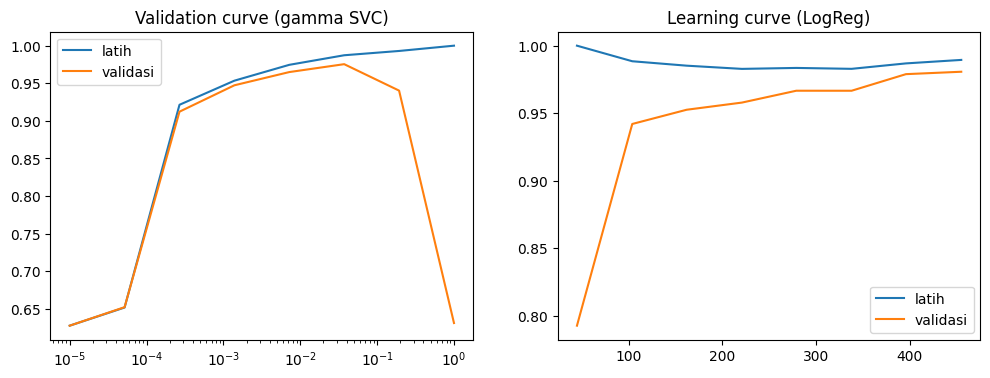

Skor asli = 0.981, skor label acak = 0.600, p-value = 0.032


In [7]:
Cs = np.logspace(-4, 2, 7)
tr, va = validation_curve(make_pipeline(StandardScaler(), SVC()), X, y, param_name="svc__gamma", param_range=np.logspace(-5, 0, 8), cv=5)
g = np.logspace(-5, 0, 8)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].semilogx(g, tr.mean(1), label="latih"); ax[0].semilogx(g, va.mean(1), label="validasi"); ax[0].legend(); ax[0].set_title("Validation curve (gamma SVC)")
sz, tr2, va2 = learning_curve(model, X, y, cv=5, train_sizes=np.linspace(.1, 1, 8))
ax[1].plot(sz, tr2.mean(1), label="latih"); ax[1].plot(sz, va2.mean(1), label="validasi"); ax[1].legend(); ax[1].set_title("Learning curve (LogReg)")
plt.show()
sc, perm, p = permutation_test_score(model, X, y, cv=5, n_permutations=30, random_state=0)
print(f"Skor asli = {sc:.3f}, skor label acak = {perm.mean():.3f}, p-value = {p:.3f}")

## 6. Latihan Praktik

### Latihan 1 – Cross-Validation pada Logistic Regression

In [8]:
for k in [3, 5, 10]:
    s = cross_val_score(model, X, y, cv=StratifiedKFold(k, shuffle=True, random_state=0)); print(f"K={k:2d}: {s.mean():.3f} ± {s.std():.3f}")

K= 3: 0.977 ± 0.009
K= 5: 0.979 ± 0.014
K=10: 0.977 ± 0.019


### Latihan 2 – Menyetel Hyperparameter dengan Grid Search dan Validation Curve

In [9]:
gs = GridSearchCV(make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)), {"logisticregression__C": np.logspace(-3, 2, 11)}, cv=5, scoring="roc_auc").fit(X, y)
print("C terbaik:", {k: round(float(v), 4) for k, v in gs.best_params_.items()}, "| AUC CV:", round(gs.best_score_, 4))

C terbaik: {'logisticregression__C': 0.3162} | AUC CV: 0.9957


### Latihan 3 – Menilai Generalisasi dengan Learning Curve dan Pemeriksaan Kebocoran Data
Bandingkan scaling yang benar (di dalam pipeline) dengan scaling di luar CV.

In [10]:
Xr = np.random.RandomState(0).randn(100, 2000); yr = np.random.RandomState(1).randint(0, 2, 100)   # data acak murni
from sklearn.feature_selection import SelectKBest, f_classif
leak = cross_val_score(LogisticRegression(max_iter=1000), SelectKBest(f_classif, k=20).fit_transform(Xr, yr), yr, cv=5).mean()
clean = cross_val_score(make_pipeline(SelectKBest(f_classif, k=20), LogisticRegression(max_iter=1000)), Xr, yr, cv=5).mean()
print(f"Seleksi fitur DI LUAR CV (bocor): {leak:.2f}  <- terlihat 'pintar' padahal datanya acak")
print(f"Seleksi fitur DI DALAM pipeline : {clean:.2f}  <- sekitar 0.5, sesuai kenyataan")

Seleksi fitur DI LUAR CV (bocor): 0.85  <- terlihat 'pintar' padahal datanya acak
Seleksi fitur DI DALAM pipeline : 0.45  <- sekitar 0.5, sesuai kenyataan


**Kesimpulan:** gunakan CV yang sesuai struktur data (stratified, group, time series), bungkus semua langkah dalam pipeline,
dan gunakan nested CV bila ingin melaporkan performa setelah penyetelan hyperparameter.